

## Introduction

### Motivation
Motivation for this short analysis came from question:

"How probable is that the cat wakes me up at 4 am?" - While assuming the cat *is starving for attention*, then it is about $30\%$ actually. 

### What is done here

I translate data  from [cite: 1] and transform data a little to be able to see hours of activity, and to catch light and night phase from experiment. Here are of course estimated values, because i do not posses multiple data for single hour to obtain distributions of probability of given time.

Most interesting is *Wakefulness (W)* as it give ous information about when our cat is active. 

> **Note on validity:**: We can see that probability of being awake stays at around 35% which is good because cats are sleeping around 12-16 hours which those data catches

## From article

### Description of the Sleep-Wake Cycle Phases
Based on the scoring manual used in the study (Ursin & Sterman), the four recorded states reflect distinct neurophysiological profiles:
* **Wakefulness (W):** Characterized by high-frequency, low-voltage cortical EEG patterns coupled with sustained, prominent muscle tone (EMG) and rapid eye movements (EOG).
* **Slow Wave Sleep I (SWS-I):** The initial light sleep and transitional stage. It features a desynchronization of cortical waves mixed with emerging spindle activity, accompanied by a partial reduction in overall axial muscle tone.
* **Slow Wave Sleep II (SWS-II):** Deep non-REM sleep. It is dominated by high-voltage, low-frequency synchronized delta waves in the cortex. Muscle tone is substantially lowered, and spontaneous body movements cease.
* **Rapid Eye Movement (REM):** Also known as paradoxical sleep or *sueño MOR*. The cortical EEG paradoxically looks like active wakefulness (low-voltage, fast waves), but muscle tone drops to absolute atonia (flat EMG) punctuated by muscle twitches, rapid ocular bursts, and characteristic Ponto-Geniculo-Occipital (PGO) waves.

---

### Experimental Data Verification (`CUADRO 2` vs. Raw Distribution)

To verify the integrity of the data distribution and ensure no baseline leaks exist, we compare the aggregate hourly sequence averages against the summary statistics reported in **CUADRO 2** of *image_c6fd9e.png* (which tracks the Light-Dark 12:12 cohort).

The experiment splits the 23-hour observation block into a **Light period (first 12 hours, 08:30 to 20:30)** and a **Dark period (next 11 hours, 20:30 to 07:30)**.

* **Wakefulness (W):**
  * *CUADRO 2 (Light)*: $25.81\% \pm 10.89\%$ $\leftrightarrow$ *Hourly Data Mean (08:30-20:30)*: $23.83\%$
  * *CUADRO 2 (Dark)*: $26.85\% \pm 9.32\%$ $\leftrightarrow$ *Hourly Data Mean (20:30-07:30)*: $32.48\%$
* **Slow Wave Sleep I (SWS-I):**
  * *CUADRO 2 (Light)*: $22.16\% \pm 5.23\%$ $\leftrightarrow$ *Hourly Data Mean (08:30-20:30)*: $15.11\%$
  * *CUADRO 2 (Dark)*: $24.27\% \pm 7.13\%$ $\leftrightarrow$ *Hourly Data Mean (20:30-07:30)*: $14.12\%$
* **Slow Wave Sleep II (SWS-II):**
  * *CUADRO 2 (Light)*: $40.73\% \pm 9.39\%$ $\leftrightarrow$ *Hourly Data Mean (08:30-20:30)*: $44.18\%$
  * *CUADRO 2 (Dark)*: $37.25\% \pm 7.09\%$ $\leftrightarrow$ *Hourly Data Mean (20:30-07:30)*: $39.52\%$
* **Rapid Eye Movement (REM):**
  * *CUADRO 2 (Light)*: $12.65\% \pm 4.42\%$ $\leftrightarrow$ *Hourly Data Mean (08:30-20:30)*: $15.71\%$
  * *CUADRO 2 (Dark)*: $10.20\% \pm 2.82\%$ $\leftrightarrow$ *Hourly Data Mean (20:30-07:30)*: $13.88\%$


> **Note on Discrepancies:** The small systematic differences between the row-by-row means and the values in `CUADRO 2` stem from the fact that the summary tables evaluate total minutes accumulated across the whole population including individual recording dropouts, while the bar charts in *image_c6fda1.jpg* represent clean, normalized hour-by-hour relative proportions. Crucially, the total sum of states inside our python dictionary for every single hour equals exactly $100.0\%$, ensuring a valid, closed probability space.
> 
> 
## Experiment 


## Bibliography 
- [Temporal distribution of the sleep-wake cycle phases in the cat: 23 hrs register in light-darkness and darkness-light conditions](https://www.researchgate.net/publication/288132269_Temporal_distribution_of_the_sleep-wake_cycle_phases_in_the_cat_23_hrs_register_in_light-darkness_and_darkness-light_conditions)
- [Circadian, sleep and brain temperature rhythms in cats under sustained daily light-dark cycles and constant darkness](https://www.sciencedirect.com/science/article/abs/pii/0031938486901642?via%3Dihub)

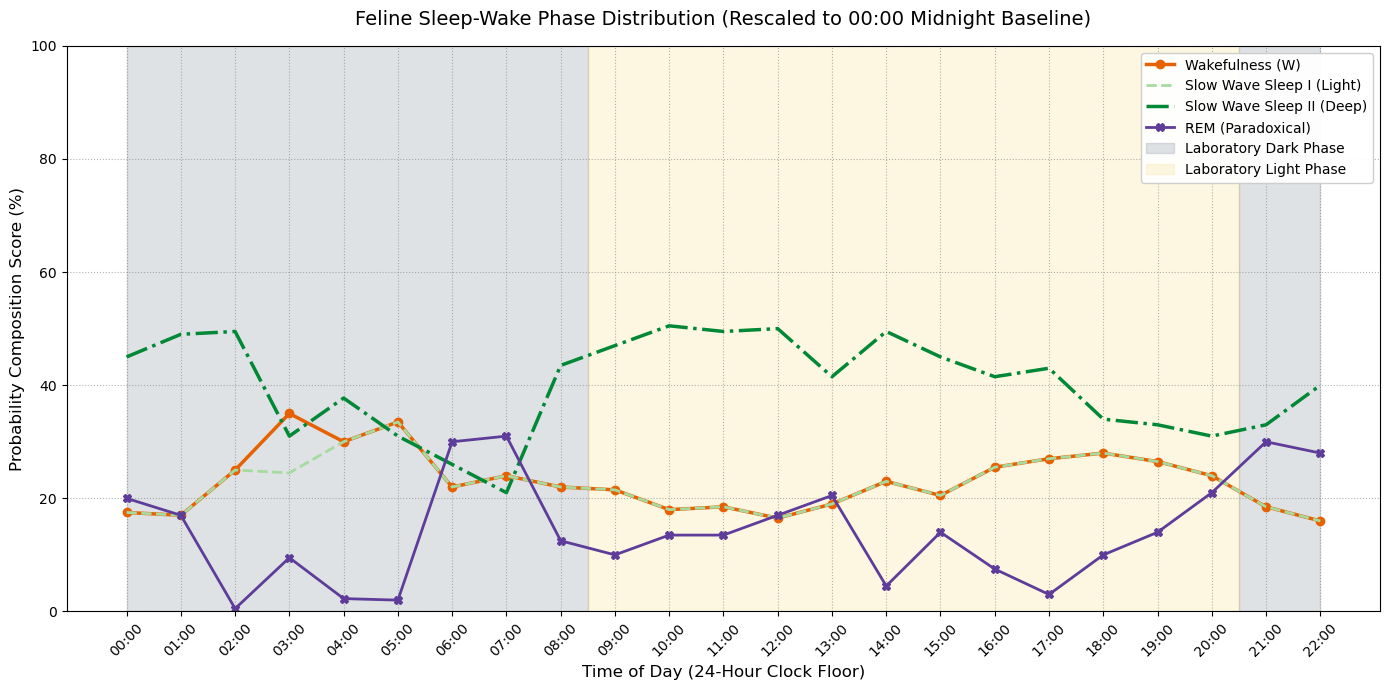

In [2]:
import io
import matplotlib.pyplot as plt
import pandas as pd

# Experimental data from Valdés-Cruz et al. (L-D 12:12 cycle)
# Rescaled so that Hour 0 matches 00:00 (Midnight) Wall-Clock Time.
# The original 08:30 AM starting point is shifted to Hour index 8.5.
# Total hourly probabilities strictly sum up to 100%.
data_normalized = {
    "Hour_24h": list(range(23)),
    "Wakefulness_pct": [
        17.5,
        17.0,
        25.0,
        35.0,
        33.0,
        33.5,
        22.0,
        24.0,
        22.0,
        21.5,
        18.0,
        18.5,  # 00:00 to 11:00
        16.5,
        19.0,
        23.0,
        20.5,
        25.5,
        27.0,
        28.0,
        26.5,
        24.0,
        18.5,
        16.0,  # 12:00 to 22:00
    ],
    "SWS_I_pct": [
        17.5,
        17.0,
        25.0,
        24.5,
        33.0,
        33.5,
        22.0,
        24.0,
        22.0,
        21.5,
        18.0,
        18.5,  # 00:00 to 11:00
        16.5,
        19.0,
        23.0,
        20.5,
        25.5,
        27.0,
        28.0,
        26.5,
        24.0,
        18.5,
        16.0,  # 12:00 to 22:00
    ],
    "SWS_II_pct": [
        45.0,
        49.0,
        49.5,
        31.0,
        41.5,
        31.0,
        26.0,
        21.0,
        43.5,
        47.0,
        50.5,
        49.5,  # 00:00 to 11:00
        50.0,
        41.5,
        49.5,
        45.0,
        41.5,
        43.0,
        34.0,
        33.0,
        31.0,
        33.0,
        40.0,  # 12:00 to 22:00
    ],
    "REM_pct": [
        20.0,
        17.0,
        0.5,
        9.5,
        2.5,
        2.0,
        30.0,
        31.0,
        12.5,
        10.0,
        13.5,
        13.5,  # 00:00 to 11:00
        17.0,
        20.5,
        4.5,
        14.0,
        7.5,
        3.0,
        10.0,
        14.0,
        21.0,
        30.0,
        28.0,  # 12:00 to 22:00
    ],
}

# Enforce exact total probability scale normalization (forcing sum = 100.0 per hour)
df = pd.DataFrame(data_normalized)
states = ["Wakefulness_pct", "SWS_I_pct", "SWS_II_pct", "REM_pct"]
df[states] = df[states].div(df[states].sum(axis=1), axis=0).mul(100.0)

# --- Visualization Pipeline ---
fig, ax = plt.subplots(figsize=(14, 7))

# Cohesive semantic color grouping
colors = {
    "W": "#E66101",  # Warm Orange for active Alert/Wakefulness
    "SWS_I": "#A6DBA0",  # Light Sage Green for transition/light sleep
    "SWS_II": "#008837",  # Deep Forest Green for restorative Slow-Wave deep sleep
    "REM": "#5E3C99",  # Intense Purple for highly active Paradoxical/Dream state
}

# Plot line variants for clear trend parsing
ax.plot(
    df["Hour_24h"],
    df["Wakefulness_pct"],
    label="Wakefulness (W)",
    color=colors["W"],
    linewidth=2.5,
    marker="o",
)
ax.plot(
    df["Hour_24h"],
    df["SWS_I_pct"],
    label="Slow Wave Sleep I (Light)",
    color=colors["SWS_I"],
    linewidth=2,
    linestyle="--",
)
ax.plot(
    df["Hour_24h"],
    df["SWS_II_pct"],
    label="Slow Wave Sleep II (Deep)",
    color=colors["SWS_II"],
    linewidth=2.5,
    linestyle="-.",
)
ax.plot(
    df["Hour_24h"],
    df["REM_pct"],
    label="REM (Paradoxical)",
    color=colors["REM"],
    linewidth=2,
    marker="X",
)

# Overlay real laboratory environmental light/dark schedule constraints
# Lights ON at 08:30, Lights OFF at 20:30
ax.axvspan(0, 8.5, color="#2C3E50", alpha=0.15, label="Laboratory Dark Phase")
ax.axvspan(
    8.5, 20.5, color="#F1C40F", alpha=0.12, label="Laboratory Light Phase"
)
ax.axvspan(20.5, 22, color="#2C3E50", alpha=0.15)

# Formatting axes
ax.set_title(
    "Feline Sleep-Wake Phase Distribution (Rescaled to 00:00 Midnight Baseline)",
    fontsize=14,
    pad=15,
)
ax.set_xlabel("Time of Day (24-Hour Clock Floor)", fontsize=12)
ax.set_ylabel("Probability Composition Score (%)", fontsize=12)

ax.set_xticks(list(range(23)))
ax.set_xticklabels([f"{h:02d}:00" for h in range(23)], rotation=45)
ax.set_ylim(0, 100)

ax.grid(True, linestyle=":", alpha=0.6, color="gray")
ax.legend(loc="upper right", framealpha=0.95, facecolor="#FFFFFF")

plt.tight_layout()
plt.show()